# Median T1 Mortality vs BCAS Rate — All 4 Policies

Line plot showing how median mortality responds to casualty rate under each policy.

In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RESULTS_PATH = _root / "data_cluster" / "saltelli_with_wrong_pooling_columns" / "results.csv"
df = pd.read_csv(RESULTS_PATH)
print(f"Loaded {len(df)} runs")

Loaded 98304 runs


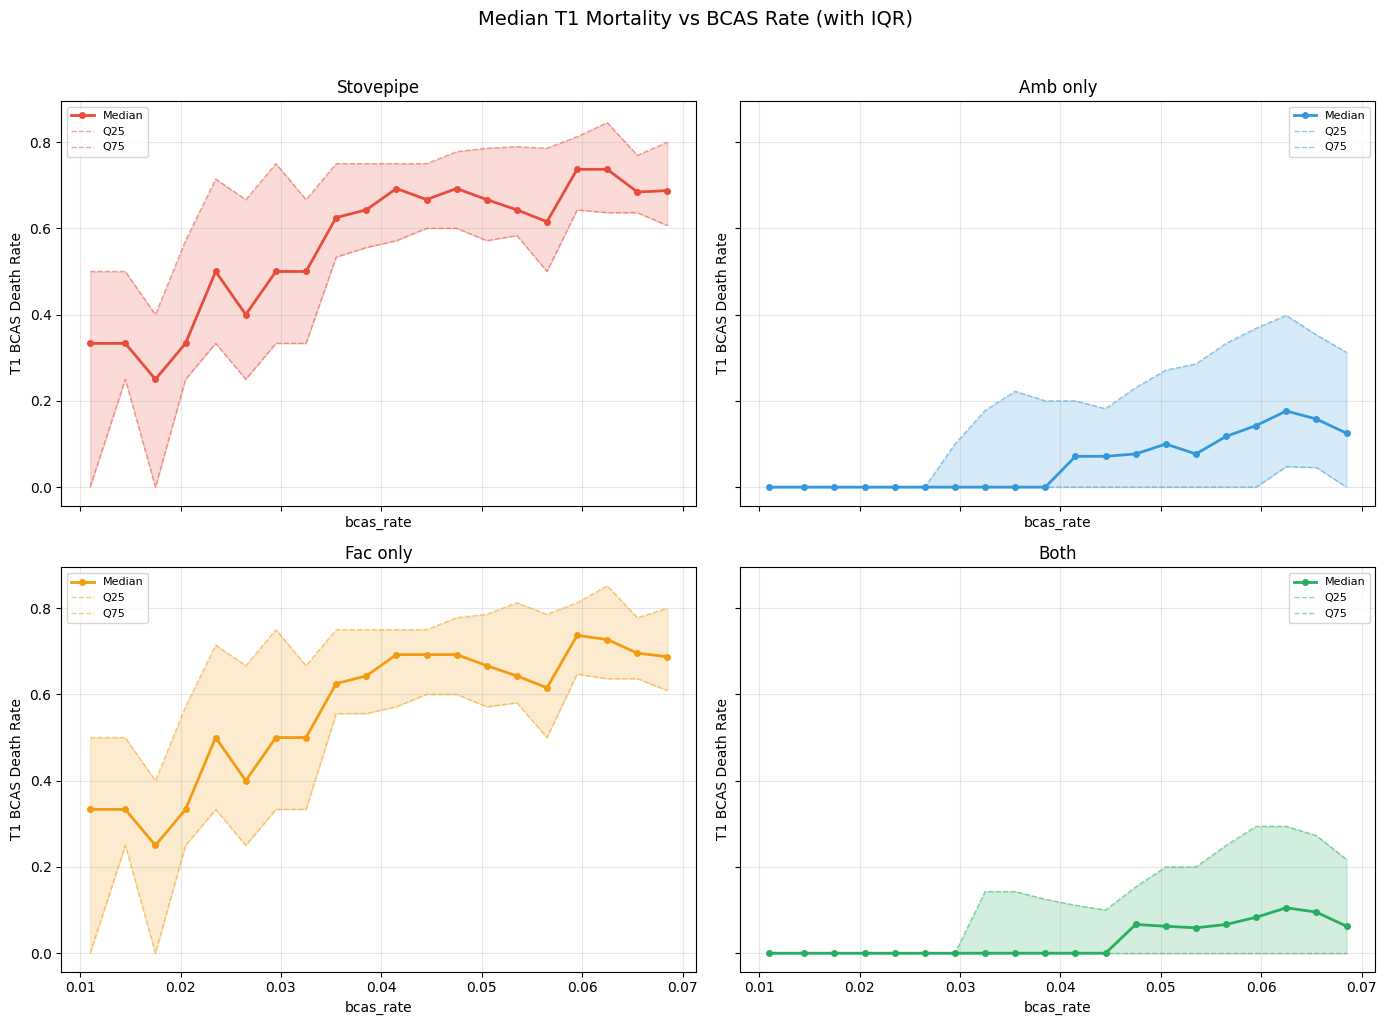

In [2]:
policies = [
    ("Stovepipe", 0, 0, "#e74c3c"),
    ("Amb only",  0, 1, "#3498db"),
    ("Fac only",  1, 0, "#f39c12"),
    ("Both",      1, 1, "#27ae60"),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=True, sharex=True)

for ax, (label, fac, amb, color) in zip(axes.flat, policies):
    sub = df[(df["facility_eligibility"] == fac) & (df["ambulance_eligibility"] == amb)]
    bins = pd.qcut(sub["bcas_rate"], q=20, duplicates="drop")
    grouped = sub.groupby(bins, observed=True)["death_rate_T1_BCAS"]
    medians = grouped.median()
    q25 = grouped.quantile(0.25)
    q75 = grouped.quantile(0.75)
    x = [iv.mid for iv in medians.index]

    ax.fill_between(x, q25.values, q75.values, alpha=0.2, color=color)
    ax.plot(x, medians.values, "o-", color=color, linewidth=2, markersize=4, label="Median")
    ax.plot(x, q25.values, "--", color=color, linewidth=1, alpha=0.5, label="Q25")
    ax.plot(x, q75.values, "--", color=color, linewidth=1, alpha=0.5, label="Q75")
    ax.set_xlabel("bcas_rate")
    ax.set_ylabel("T1 BCAS Death Rate")
    ax.set_title(label)
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

fig.suptitle("Median T1 Mortality vs BCAS Rate (with IQR)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## All 4 Policies on One Plot

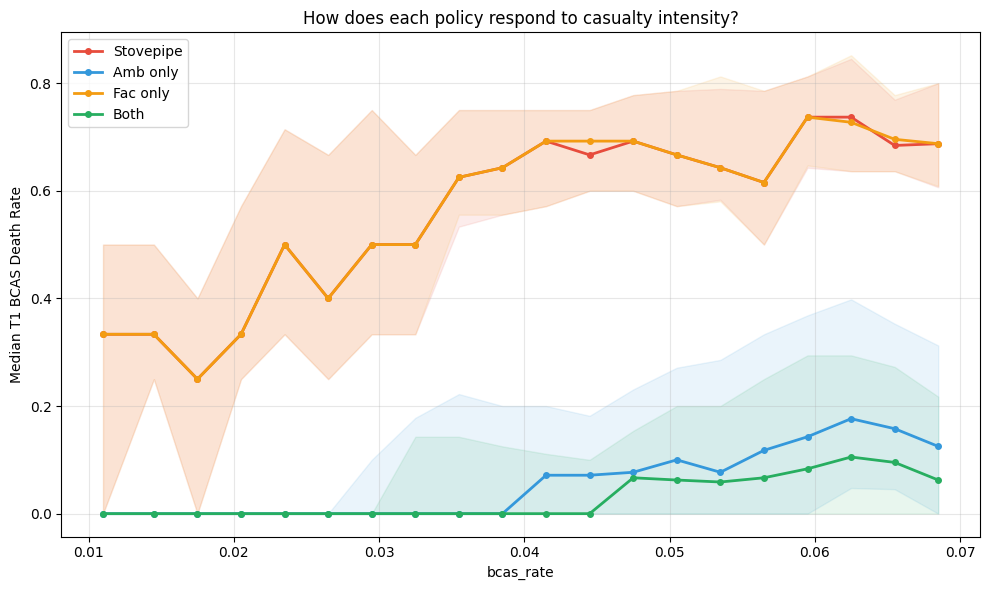

In [3]:
fig, ax = plt.subplots(figsize=(10, 6))

for label, fac, amb, color in policies:
    sub = df[(df["facility_eligibility"] == fac) & (df["ambulance_eligibility"] == amb)]
    bins = pd.qcut(sub["bcas_rate"], q=20, duplicates="drop")
    grouped = sub.groupby(bins, observed=True)["death_rate_T1_BCAS"]
    medians = grouped.median()
    q25 = grouped.quantile(0.25)
    q75 = grouped.quantile(0.75)
    x = [iv.mid for iv in medians.index]

    ax.fill_between(x, q25.values, q75.values, alpha=0.1, color=color)
    ax.plot(x, medians.values, "o-", color=color, linewidth=2, markersize=4, label=label)

ax.set_xlabel("bcas_rate")
ax.set_ylabel("Median T1 BCAS Death Rate")
ax.set_title("How does each policy respond to casualty intensity?")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()